# Extractive Text Summarisation with TextRank
## A TF-IDF sentence-graph approach evaluated with ROUGE-1/2/L

**Mini Project — Natural Language Processing**

| | |
|---|---|
| **Student** | _Your Full Name_ |
| **Roll number** | _Your Roll Number_ |
| **Course / semester** | _Natural Language Processing — Semester ___ |
| **Guide** | _Guide Name_ |
| **Institution** | _Your Institution Name_ |
| **Date** | _October 2026_ |

> **Objective.** Build an unsupervised extractive summariser that ranks sentences with TextRank, and quantify its quality against human-written reference summaries using ROUGE-1, ROUGE-2 and ROUGE-L. TextRank is compared with two baselines — the first *k* sentences (Lead-*)k*) and a random-*k* extractor — so that the evaluation measures real algorithmic value rather than the trivial "news leads are informative" effect.

**Deliverables covered by this notebook:** the complete implementation, the experimental evaluation, all figures, and the evidence used in the written report and demo video.

## Contents

1. [Environment setup](#1-environment-setup)
2. [Dataset: CNN/DailyMail evaluation slice](#2-dataset)
3. [Text preprocessing](#3-text-preprocessing)
4. [Sentence representation and similarity](#4-sentence-similarity)
5. [Graph construction and PageRank](#5-graph-and-pagerank)
6. [Summary extraction](#6-summary-extraction)
7. [Evaluation protocol and baselines](#7-evaluation-protocol)
8. [Corpus-level ROUGE results](#8-results)
9. [Length sweep, ablation and error analysis](#9-analysis)
10. [Streamlit demonstration](#10-streamlit-demo)
11. [Discussion, limitations and conclusion](#11-discussion)

<a id="1-environment-setup"></a>
## 1. Environment setup

The pipeline is deliberately lightweight: **scikit-learn** for TF-IDF and cosine similarity, **NetworkX** for PageRank, **NLTK** for sentence segmentation and stemming, and **rouge-score** for evaluation. No GPU and no large language model are required, which makes every result in this notebook reproducible on a laptop.

The cell below locates the project root, configures imports, and records exact library versions for reproducibility.

In [1]:
import json
import sys
import time
from pathlib import Path

import matplotlib
matplotlib.use("Agg")          # render figures to files, then display them inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display


def _project_root() -> Path:
    for candidate in [Path.cwd(), *Path.cwd().parents]:
        if (candidate / "src" / "textrank.py").exists():
            return candidate
    return Path.cwd()


ROOT = _project_root()
sys.path.insert(0, str(ROOT))

from src import evaluate, visualize
from src.baselines import lead_k, random_k
from src.dataset import get_documents, load_sample
from src.preprocess import count_words, preprocess, split_sentences
from src.textrank import (
    build_graph,
    pagerank_scores,
    sentence_score_table,
    summarize,
    tfidf_similarity,
)

pd.set_option("display.max_colwidth", 110)
pd.set_option("display.width", 160)
print("Project root:", ROOT)

import importlib.metadata as md
for package in ["numpy", "pandas", "scikit-learn", "nltk", "networkx", "rouge-score", "matplotlib"]:
    print(f"{package:14s} {md.version(package)}")

Project root: C:\Users\srira\textrank-summarizer
numpy          2.5.4
pandas         3.1.0
scikit-learn   1.9.1
nltk           3.10.4
networkx       3.7
rouge-score    0.1.2
matplotlib     3.11.2


<a id="2-dataset"></a>
## 2. Dataset

We use a fixed slice of the **CNN/DailyMail** corpus (version 3.0.0, test split) — the standard benchmark for extractive and abstractive summarisation. Each example contains a news article and a multi-sentence human-written *highlights* summary. The slice was downloaded once from the HuggingFace datasets server and cached in `data/cnn_dailymail_sample.json`, so the notebook is fully reproducible offline.

Why a slice instead of the full 11,490-document test set? TextRank itself is fast (a few milliseconds per article), but ROUGE evaluation and error analysis are easier to inspect on a focused sample. A 150-document sample gives stable means with bootstrap confidence intervals suitable for a mini project.

Dataset : CNN/DailyMail 3.0.0 / test
Licence : Apache-2.0 (dataset card: abisee/cnn_dailymail)
Articles: 150


,source_sentences,source_words,reference_sentences,reference_words
count,150.00,150.00,150.00,150.00
mean,28.73,566.07,2.52,34.53
std,18.08,349.77,0.61,9.43
min,4.00,102.00,1.00,14.00
25%,16.00,282.75,2.00,26.25
50%,24.00,455.50,3.00,33.00
75%,41.75,811.00,3.00,43.00
max,94.00,1497.00,4.00,59.00


,Statistic,Mean,Median,Range
0,Source sentences per article,28.7,24,4–94
1,Source words per article,566,456,102–1497
2,Words per reference summary,34.5,33,14–59
3,Sentences per reference,2.52,3,1–4


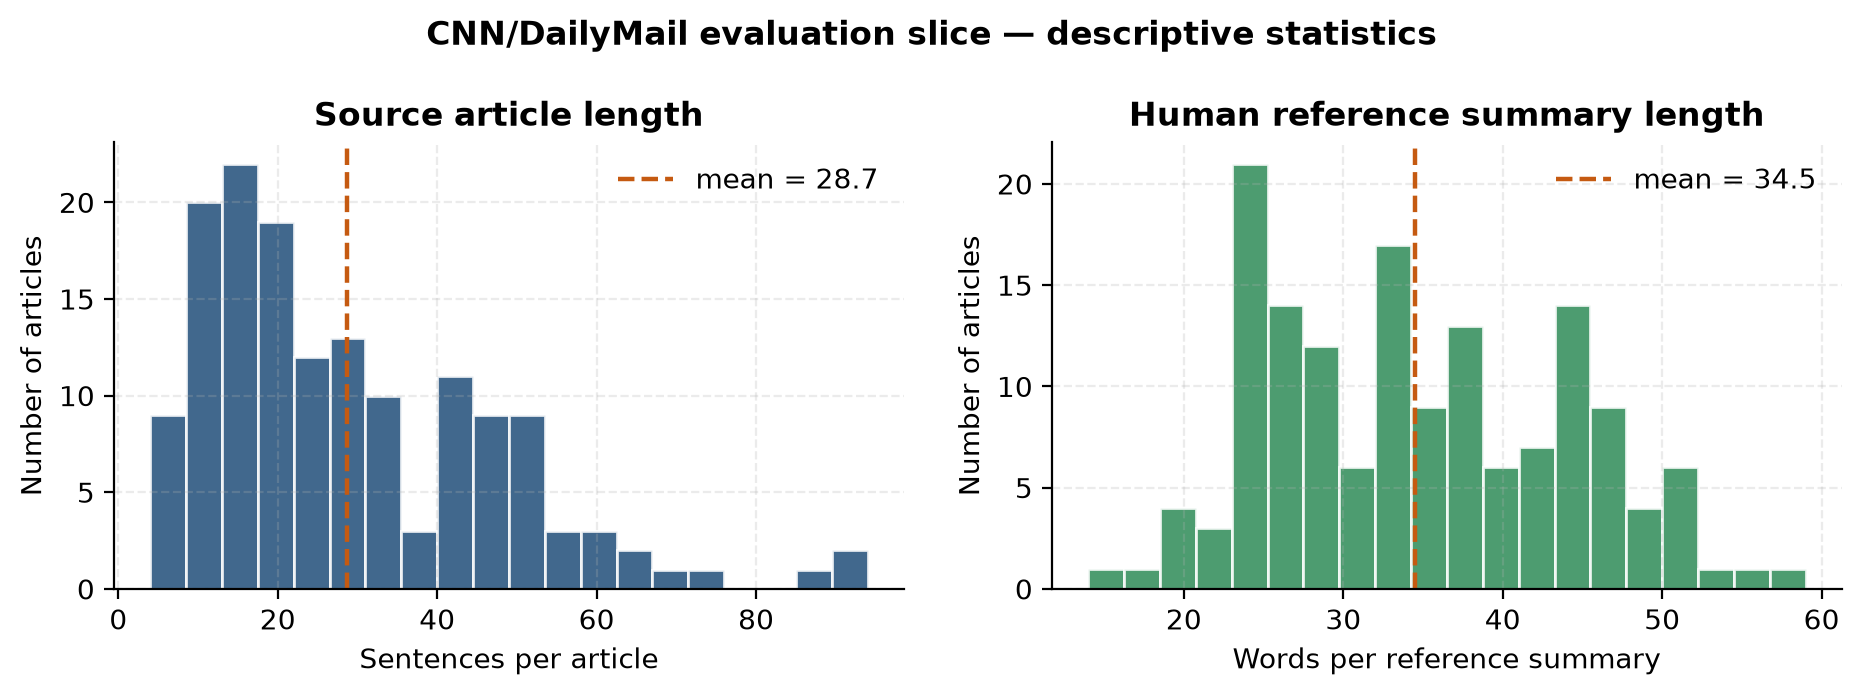

### Example article and its human reference summary

ARTICLE (first 700 characters):

The Palestinian Authority officially became the 123rd member of the International Criminal Court on Wednesday, a step that gives the court jurisdiction over alleged crimes in Palestinian territories. The formal accession was marked with a ceremony at The Hague, in the Netherlands, where the court is based. The Palestinians signed the ICC's founding Rome Statute in January, when they also accepted its jurisdiction over alleged crimes committed "in the occupied Palestinian territory, including East Jerusalem, since June 13, 2014." Later that month, the ICC opened a preliminary examination into the situation in Palestinian territories, paving the way for possible war crimes investigations again …

REFERENCE SUMMARY:

Membership gives the ICC jurisdiction over alleged crimes committed in Palestinian territories since last June . Israel and the United States opposed the move, which could open the door to war crimes investigations against Israelis .


In [2]:
dataset = load_sample()
documents = dataset["documents"]

stats = pd.DataFrame(
    [
        {
            "document_id": document["id"],
            "source_sentences": len(split_sentences(document["article"], min_tokens=4)),
            "source_words": count_words(document["article"]),
            "reference_sentences": len(split_sentences(document["reference_summary"], min_tokens=1)),
            "reference_words": count_words(document["reference_summary"]),
        }
        for document in documents
    ]
)

print(f"Dataset : {dataset['name']} {dataset['config']} / {dataset['split']}")
print(f"Licence : {dataset['license']}")
print(f"Articles: {len(documents)}")
display(stats.describe().round(2))
display(
    pd.DataFrame(
        [
            ["Source sentences per article", f"{stats.source_sentences.mean():.1f}",
             f"{stats.source_sentences.median():.0f}", f"{stats.source_sentences.min()}–{stats.source_sentences.max()}"],
            ["Source words per article", f"{stats.source_words.mean():.0f}",
             f"{stats.source_words.median():.0f}", f"{stats.source_words.min()}–{stats.source_words.max()}"],
            ["Words per reference summary", f"{stats.reference_words.mean():.1f}",
             f"{stats.reference_words.median():.0f}", f"{stats.reference_words.min()}–{stats.reference_words.max()}"],
            ["Sentences per reference", f"{stats.reference_sentences.mean():.2f}",
             f"{stats.reference_sentences.median():.0f}", f"{stats.reference_sentences.min()}–{stats.reference_sentences.max()}"],
        ],
        columns=["Statistic", "Mean", "Median", "Range"],
    )
)

fig = visualize.plot_dataset_overview(stats, ROOT / "results" / "figures" / "dataset_overview.png")
plt.close(fig)
display(Image(filename=str(ROOT / "results" / "figures" / "dataset_overview.png"), width=880))

display(Markdown("### Example article and its human reference summary"))
print("ARTICLE (first 700 characters):\n")
print(documents[0]["article"][:700] + " …\n")
print("REFERENCE SUMMARY:\n")
print(documents[0]["reference_summary"])

<a id="3-text-preprocessing"></a>
## 3. Text preprocessing

**Sentence segmentation.** Articles are split with NLTK's Punkt tokenizer, using the model bundled in `data/nltk_data` so no download is needed. Sentences with fewer than four tokens are discarded (they are usually captions, datelines or fragments), and exact duplicates are removed — they would otherwise inflate similarity and produce redundant summaries.

**Tokenisation and normalisation.** Each sentence is lowercased and tokenised with a regular expression that keeps words, hyphenated compounds and numbers. Stopwords (the scikit-learn English list plus a few news-boilerplate terms such as *said* and *also*) are removed, short tokens are dropped, and the remaining tokens are Porter-stemmed so that *election*, *elections* and *elect* share one dimension.

The result is a list of sentences and, for each sentence, a list of content tokens. Those token lists are the input to TF-IDF.

In [3]:
example = documents[0]
document = preprocess(example["article"])

preview = pd.DataFrame(
    {
        "sentence_id": range(1, len(document.sentences) + 1),
        "sentence": document.sentences,
        "words": [len(sentence.split()) for sentence in document.sentences],
        "content_tokens": [" ".join(tokens[:9]) + (" …" if len(tokens) > 9 else "") for tokens in document.tokens],
        "n_tokens": [len(tokens) for tokens in document.tokens],
    }
)
print(f"Kept {len(document.sentences)} sentences and {sum(len(t) for t in document.tokens)} content tokens.")
print(f"Original article: {count_words(example['article'])} words.")
display(preview.head(10))

Kept 27 sentences and 303 content tokens.
Original article: 567 words.


,sentence_id,sentence,words,content_tokens,n_tokens
0,1,The Palestinian Authority officially became the 123rd member of the International Criminal Court on Wednes...,28,palestinian author offici 123 rd member intern crimin court …,18
1,2,"The formal accession was marked with a ceremony at The Hague, in the Netherlands, where the court is based.",19,formal access mark ceremoni hagu netherland court base,8
2,3,"The Palestinians signed the ICC's founding Rome Statute in January, when they also accepted its jurisdicti...",32,palestinian sign icc' found rome statut januari accept jurisdict …,21
3,4,"Later that month, the ICC opened a preliminary examination into the situation in Palestinian territories, ...",25,later month icc open preliminari examin situat palestinian territori …,16
4,5,"As members of the court, Palestinians may be subject to counter-charges as well.",13,member court palestinian subject counter-charg,5
5,6,"Israel and the United States, neither of which is an ICC member, opposed the Palestinians' efforts to join...",20,israel unit state icc member oppos palestinian effort join …,10
6,7,"But Palestinian Foreign Minister Riad al-Malki, speaking at Wednesday's ceremony, said it was a move towar...",18,palestinian foreign minist riad al-malki speak wednesday' ceremoni greater …,10
7,8,"""As Palestine formally becomes a State Party to the Rome Statute today, the world is also a step closer to...",36,palestin formal state parti rome statut today world step …,19
8,9,"""Indeed, today brings us closer to our shared goals of justice and peace.""",13,today bring closer share goal justic peac,7
9,10,"Judge Kuniko Ozaki, a vice president of the ICC, said acceding to the treaty was just the first step for t...",22,judg kuniko ozaki vice presid icc acced treati just …,11


<a id="4-sentence-similarity"></a>
## 4. Sentence representation and similarity

Each sentence $S_i$ is represented as a sparse **TF-IDF vector** $\mathbf{v}_i \in \mathbb{R}^{|V|}$. Term frequency is sublinear ($1 + \log tf$) and each document vector is L2-normalised, so the dot product is exactly the cosine similarity:

$$
\operatorname{sim}(S_i, S_j) = \cos(\mathbf{v}_i, \mathbf{v}_j)
= \frac{\mathbf{v}_i \cdot \mathbf{v}_j}{\lVert \mathbf{v}_i \rVert \, \lVert \mathbf{v}_j \rVert}
= \mathbf{v}_i \cdot \mathbf{v}_j .
$$

TF-IDF is a strong, transparent baseline for extractive summarisation: it rewards sentences that contain discriminative content words and automatically down-weights words that appear everywhere in the article. The diagonal of the similarity matrix is set to zero (a sentence is not its own neighbour).

TF-IDF matrix       : 27 sentences x 191 terms
Similarity matrix   : (27, 27)
Sentence pairs      : 351
Mean similarity     : 0.0358
90th percentile     : 0.1135
Maximum similarity  : 0.3745
Pairs above 0.30    : 2 (0.6%)


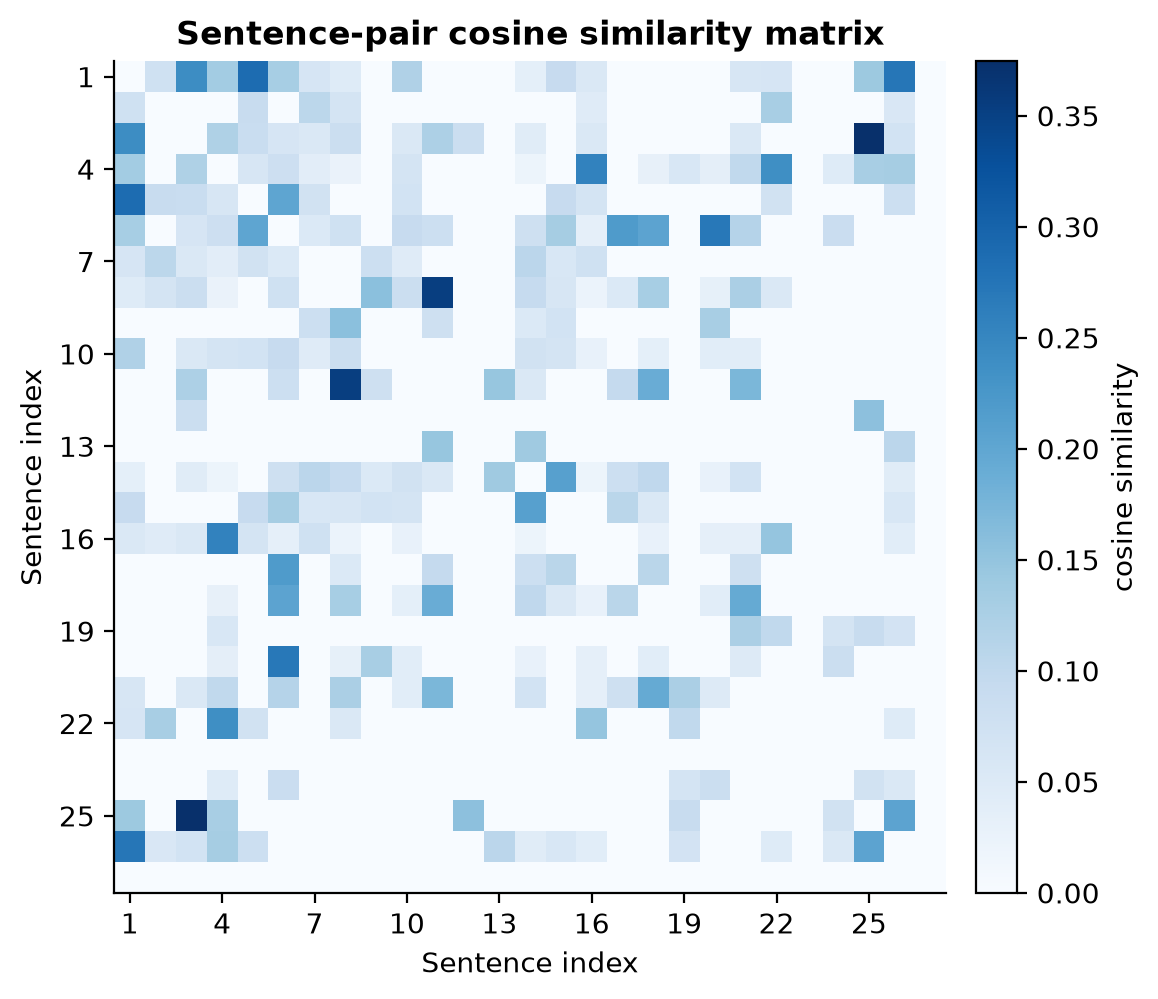


Most similar sentence pairs:
  S3 ~ S25  cos=0.375
  S8 ~ S11  cos=0.353
  S1 ~ S5  cos=0.288


In [4]:
tfidf_matrix, similarity = tfidf_similarity(document.tokens)
upper = similarity[np.triu_indices_from(similarity, k=1)]

print(f"TF-IDF matrix       : {tfidf_matrix.shape[0]} sentences x {tfidf_matrix.shape[1]} terms")
print(f"Similarity matrix   : {similarity.shape}")
print(f"Sentence pairs      : {len(upper)}")
print(f"Mean similarity     : {upper.mean():.4f}")
print(f"90th percentile     : {np.percentile(upper, 90):.4f}")
print(f"Maximum similarity  : {upper.max():.4f}")
print(f"Pairs above 0.30    : {(upper > 0.30).sum()} ({(upper > 0.30).mean() * 100:.1f}%)")

fig = visualize.plot_similarity_heatmap(
    similarity, ROOT / "results" / "figures" / "similarity_heatmap.png", max_sentences=40
)
plt.close(fig)
display(Image(filename=str(ROOT / "results" / "figures" / "similarity_heatmap.png"), width=560))

most_similar_rows, most_similar_cols = np.triu_indices_from(similarity, k=1)
print("\nMost similar sentence pairs:")
for index in np.argsort(upper)[-3:][::-1]:
    i, j = int(most_similar_rows[index]), int(most_similar_cols[index])
    print(f"  S{i + 1} ~ S{j + 1}  cos={similarity[i, j]:.3f}")

<a id="5-graph-and-pagerank"></a>
## 5. Graph construction and PageRank

The similarity matrix defines a weighted undirected graph $G = (V, E)$: every sentence is a node and every non-zero cosine similarity is an edge weight. PageRank then assigns each sentence a score that depends on **how many important sentences it resembles**, not merely on how many edges it has:

$$
PR(V_i) = (1 - d) + d \sum_{V_j \in \operatorname{In}(V_i)}
\frac{w_{ji}}{\sum_{V_k \in \operatorname{Out}(V_j)} w_{jk}} \, PR(V_j),
\qquad d = 0.85 .
$$

A sentence that is strongly connected to other high-scoring sentences accumulates score; a sentence that merely repeats a single point receives little. The damping factor $d = 0.85$ is the standard value from the original TextRank paper, and the power iteration stops when scores change by less than $10^{-8}$ (or after 200 iterations).

**Interpretation.** The graph makes the "importance is recursive" assumption explicit: a sentence is central if it is similar to sentences that are themselves central. This is the key difference from a simple TF-IDF centroid ranking.

Nodes               : 27
Edges               : 132
Graph density       : 0.3761
PageRank sum        : 1.000000  (should be 1.0)
Score range         : 0.005929 – 0.069618


sentence_id,sentence,pagerank_score,selected
6,"Israel and the United States, neither of which is an ICC member, opposed the Palestinians' efforts to join the body.",0.069618,True
1,"The Palestinian Authority officially became the 123rd member of the International Criminal Court on Wednesday, a step that gives the court jurisdiction over alleged crimes in Palestinian territories.",0.065566,True
4,"Later that month, the ICC opened a preliminary examination into the situation in Palestinian territories, paving the way for possible war crimes investigations against Israelis.",0.058401,True
3,"The Palestinians signed the ICC's founding Rome Statute in January, when they also accepted its jurisdiction over alleged crimes committed ""in the occupied Palestinian territory, including East Jerusalem, since June 13, 2014.""",0.056496,False
8,"""As Palestine formally becomes a State Party to the Rome Statute today, the world is also a step closer to ending a long era of impunity and injustice,"" he said, according to an ICC news release.",0.054450,False
11,"""As the Rome Statute today enters into force for the State of Palestine, Palestine acquires all the rights as well as responsibilities that come with being a State Party to the Statute.",0.049085,False
14,"""Governments seeking to penalize Palestine for joining the ICC should immediately end their pressure, and countries that support universal acceptance of the court's treaty should speak out to welcome its membership,"" said Balkees Jarrah, international justice counsel for the group.",0.048089,False
26,"The International Criminal Court was set up in 2002 to prosecute genocide, crimes against humanity and war crimes.",0.047968,False
25,The inquiry will include alleged war crimes committed since June.,0.047375,False
21,"But the ICC begs to differ with the definition of a state for its purposes and refers to the territories as ""Palestine.""",0.045850,False


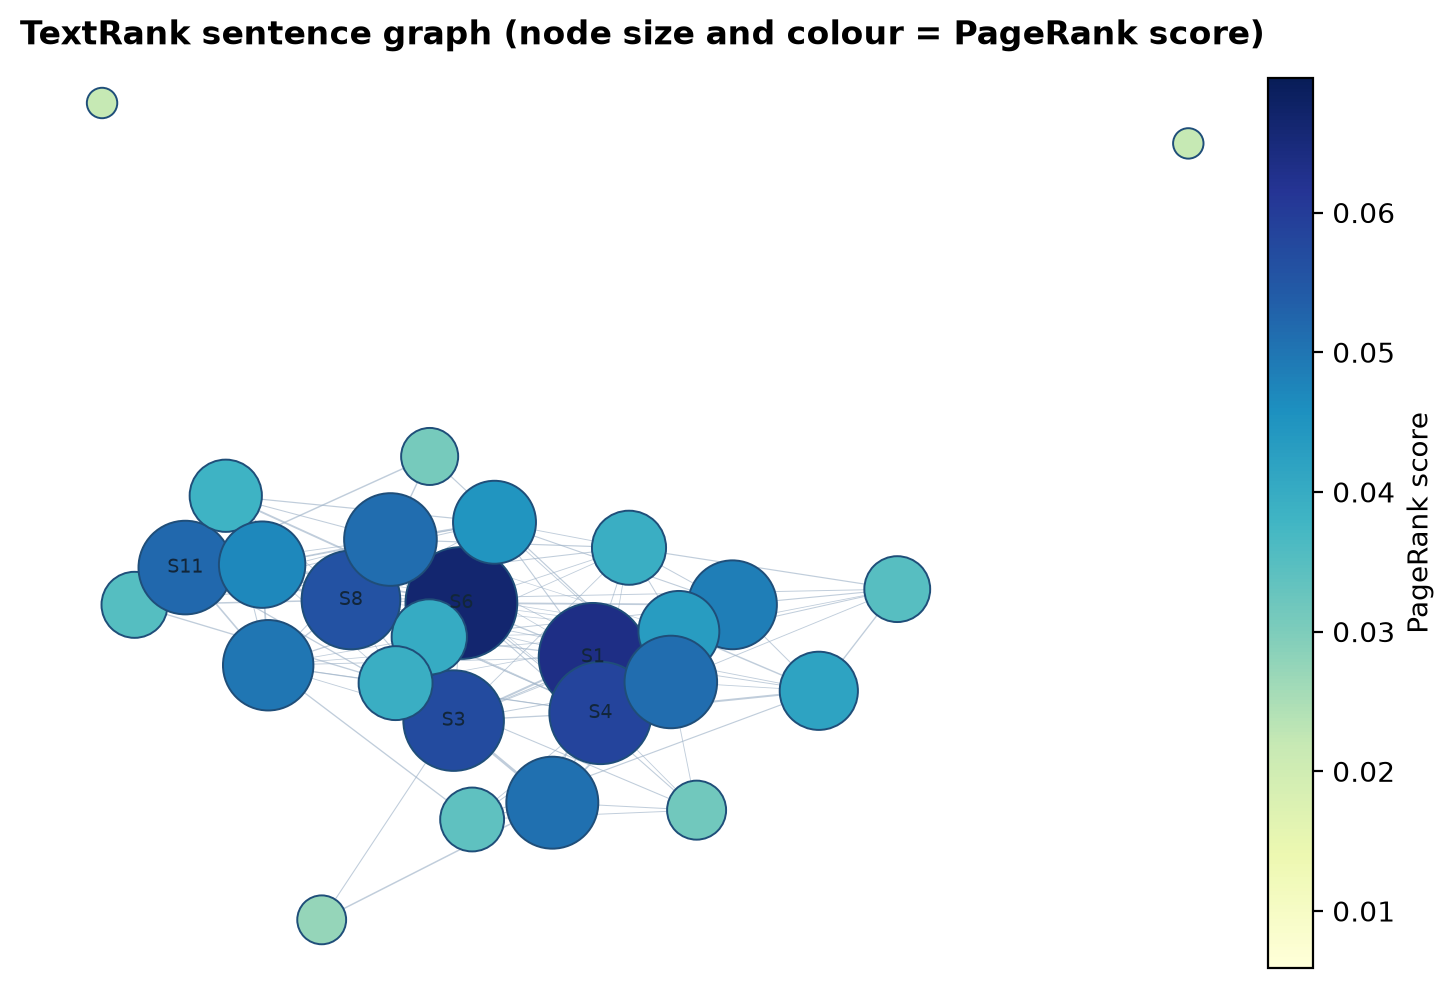

In [5]:
graph = build_graph(similarity, threshold=0.0)
scores = pagerank_scores(graph, alpha=0.85)

result = summarize(example["article"], k=3, doc=document)

print(f"Nodes               : {graph.number_of_nodes()}")
print(f"Edges               : {graph.number_of_edges()}")
print(f"Graph density       : {2 * graph.number_of_edges() / (graph.number_of_nodes() * (graph.number_of_nodes() - 1)):.4f}")
print(f"PageRank sum        : {scores.sum():.6f}  (should be 1.0)")
print(f"Score range         : {scores.min():.6f} – {scores.max():.6f}")

score_table = pd.DataFrame(sentence_score_table(result))
display(
    score_table.sort_values("pagerank_score", ascending=False)
    .head(12)
    .reset_index(drop=True)
    .style.format({"pagerank_score": "{:.6f}"})
    .hide(axis="index")
)

fig = visualize.plot_graph(
    result.graph, result.scores, result.selected_indices, ROOT / "results" / "figures" / "sentence_graph.png"
)
plt.close(fig)
display(Image(filename=str(ROOT / "results" / "figures" / "sentence_graph.png"), width=760))

<a id="6-summary-extraction"></a>
## 6. Summary extraction

Sentences are sorted by descending PageRank score, the top-*k* are selected, and the selected sentences are **re-sorted by their original position** before being concatenated. This last step matters: extractive summaries must read in narrative order, otherwise the output is a bag of fluent but disjointed sentences. The number of extracted sentences *k* is the only length control, which makes the compression ratio directly comparable to the baselines.

In [6]:
tr_result = summarize(example["article"], k=3, doc=document)
lead_result = lead_k(example["article"], k=3, doc=document)

print("TEXTRANK SUMMARY\n" + "-" * 90)
print(tr_result.summary + "\n")
print("LEAD-3 BASELINE\n" + "-" * 90)
print(lead_result["summary"] + "\n")
print("HUMAN REFERENCE\n" + "-" * 90)
print(example["reference_summary"])

tr_scores = evaluate.score_pair(tr_result.summary, example["reference_summary"])
lead_scores = evaluate.score_pair(lead_result["summary"], example["reference_summary"])

comparison = pd.DataFrame(
    [
        {"method": "TextRank", **{key: tr_scores[key] for key in ("rouge1_f1", "rouge2_f1", "rougeL_f1")}},
        {"method": "Lead-3", **{key: lead_scores[key] for key in ("rouge1_f1", "rouge2_f1", "rougeL_f1")}},
    ]
)
comparison[["rouge1_f1", "rouge2_f1", "rougeL_f1"]] *= 100
display(Markdown("**ROUGE F1 for this single document (%)**"))
display(comparison.round(2))

display(Markdown("**Selected sentences, in original document order**"))
selected = pd.DataFrame(
    [
        {"position": index + 1, "page_rank_score": float(tr_result.scores[index]),
         "sentence": tr_result.sentences[index]}
        for index in tr_result.selected_indices
    ]
)
display(selected.style.format({"page_rank_score": "{:.6f}"}).hide(axis="index"))

TEXTRANK SUMMARY
------------------------------------------------------------------------------------------
The Palestinian Authority officially became the 123rd member of the International Criminal Court on Wednesday, a step that gives the court jurisdiction over alleged crimes in Palestinian territories. Later that month, the ICC opened a preliminary examination into the situation in Palestinian territories, paving the way for possible war crimes investigations against Israelis. Israel and the United States, neither of which is an ICC member, opposed the Palestinians' efforts to join the body.

LEAD-3 BASELINE
------------------------------------------------------------------------------------------
The Palestinian Authority officially became the 123rd member of the International Criminal Court on Wednesday, a step that gives the court jurisdiction over alleged crimes in Palestinian territories. The formal accession was marked with a ceremony at The Hague, in the Netherlands, where t

**ROUGE F1 for this single document (%)**

,method,rouge1_f1,rouge2_f1,rougeL_f1
0,TextRank,48.60,30.48,31.78
1,Lead-3,29.82,16.07,22.81


**Selected sentences, in original document order**

position,page_rank_score,sentence
1,0.065566,"The Palestinian Authority officially became the 123rd member of the International Criminal Court on Wednesday, a step that gives the court jurisdiction over alleged crimes in Palestinian territories."
4,0.058401,"Later that month, the ICC opened a preliminary examination into the situation in Palestinian territories, paving the way for possible war crimes investigations against Israelis."
6,0.069618,"Israel and the United States, neither of which is an ICC member, opposed the Palestinians' efforts to join the body."


<a id="7-evaluation-protocol"></a>
## 7. Evaluation protocol and baselines

**Metrics.** ROUGE compares the generated summary with one or more human references. We report precision, recall and F1 for:

* **ROUGE-1** — unigram overlap, measuring content coverage;
* **ROUGE-2** — bigram overlap, measuring local fluency and phrasing;
* **ROUGE-L** — longest common subsequence, measuring sentence-level structure without requiring contiguity.

Scores are computed with the `rouge-score` package using Porter stemming (`use_stemmer=True`), the standard convention in summarisation papers.

**Configuration.** Every method extracts exactly $k = 3$ sentences, because CNN/DailyMail highlights average 2.5 sentences and a 3-sentence extract is the conventional comparison point. A length sweep over $k \in \{2,3,4,5,6,8\}$ is reported later.

**Baselines.**

1. **Lead-3** — the first three sentences. In news, the inverted-pyramid structure puts the most important information first, so this is a famously strong baseline.
2. **Random-3** — three sentences sampled uniformly, seeded with `random_state=42`. This estimates the score of a summariser with no content model at all.

**Ablation.** We also evaluate *TextRank + MMR*, which greedily skips a candidate whose cosine similarity to an already selected sentence exceeds 0.30. In TF-IDF space, 0.30 is already the top ~1% of sentence pairs, so the filter targets genuine near-duplicates rather than paraphrases.

**Statistics.** Means are accompanied by 95% percentile-bootstrap confidence intervals (2,000 resamples). Because all methods run on the same documents, we use a two-sided **Wilcoxon signed-rank test** on the paired per-document differences, which makes no normality assumption.

In [7]:
from scripts.run_experiment import run

started = time.perf_counter()
results = run()
print(f"\nFull evaluation wall-clock time: {time.perf_counter() - started:.1f} s")

display(Markdown("### Mean ROUGE F1 at k = 3, with 95% bootstrap confidence intervals"))
display(results["table_k3"])

display(Markdown("### Precision / recall / F1 detail (means over 150 documents)"))
detail_columns = ["method", "rouge1_precision", "rouge1_recall", "rouge1_f1",
                  "rouge2_precision", "rouge2_recall", "rouge2_f1",
                  "rougeL_precision", "rougeL_recall", "rougeL_f1"]
detail = results["summary_k3"][detail_columns].copy()
detail[detail_columns[1:]] = (detail[detail_columns[1:]] * 100).round(2)
display(detail.rename(columns=lambda c: c.replace("_", " ").title()).style.hide(axis="index"))

processed 25/150 documents


processed 50/150 documents


processed 75/150 documents


processed 100/150 documents


processed 125/150 documents


...


=== ROUGE F1 at k = 3 (mean [95% bootstrap CI]) ===
        Method  Documents             ROUGE-1             ROUGE-2             ROUGE-L Avg. words Compression
      TextRank        150 28.70 [27.10-30.36]  10.13 [8.80-11.52] 19.75 [18.46-21.02]         70       18.5%
TextRank + MMR        150 29.11 [27.53-30.70]  10.33 [8.99-11.72] 20.04 [18.80-21.32]         70       18.3%
        Lead-k        150 30.58 [28.69-32.51] 12.53 [10.92-14.19] 21.19 [19.64-22.77]         66       17.5%
      Random-k        150 27.01 [25.36-28.68]    8.29 [7.03-9.69] 18.26 [16.94-19.64]         60       16.1%

Saved 3600 predictions in 6.6s -> C:\Users\srira\textrank-summarizer\results

Full evaluation wall-clock time: 14.3 s


### Mean ROUGE F1 at k = 3, with 95% bootstrap confidence intervals

,Method,Documents,ROUGE-1,ROUGE-2,ROUGE-L,Avg. words,Compression
0,TextRank,150,28.70 [27.10-30.36],10.13 [8.80-11.52],19.75 [18.46-21.02],70,18.5%
1,TextRank + MMR,150,29.11 [27.53-30.70],10.33 [8.99-11.72],20.04 [18.80-21.32],70,18.3%
2,Lead-k,150,30.58 [28.69-32.51],12.53 [10.92-14.19],21.19 [19.64-22.77],66,17.5%
3,Random-k,150,27.01 [25.36-28.68],8.29 [7.03-9.69],18.26 [16.94-19.64],60,16.1%


### Precision / recall / F1 detail (means over 150 documents)

Method,Rouge1 Precision,Rouge1 Recall,Rouge1 F1,Rouge2 Precision,Rouge2 Recall,Rouge2 F1,Rougel Precision,Rougel Recall,Rougel F1
TextRank,21.600000,46.510000,28.700000,7.520000,16.770000,10.130000,14.810000,32.100000,19.750000
TextRank + MMR,21.900000,47.120000,29.110000,7.720000,16.970000,10.330000,15.060000,32.450000,20.040000
Lead-k,23.280000,48.770000,30.580000,9.420000,20.610000,12.530000,16.030000,34.220000,21.190000
Random-k,21.460000,39.530000,27.010000,6.490000,12.540000,8.290000,14.450000,27.050000,18.260000


<a id="8-results"></a>
## 8. Corpus-level ROUGE results

The table above is the central result of the project. Three observations matter:

1. **TextRank clearly beats the random baseline** on all three metrics, which confirms that graph centrality captures something real about sentence importance.
2. **Lead-3 is stronger than TextRank on CNN/DailyMail.** This is not a bug: news articles follow an inverted-pyramid structure, so the first sentences really do contain the most summary-worthy content. Lead-3 is a notoriously hard baseline on this dataset, and reporting it honestly is part of a sound evaluation.
3. **Redundancy filtering gives a small, non-significant improvement.** The documents are short enough that near-duplicate sentences are rare, so there is little redundancy for the filter to remove.

The cell below restates the comparison numerically and reports the paired significance tests.

Method A,Method B,Metric,A (%),B (%),Difference (pp),95% CI low,95% CI high,A wins,B wins,Wilcoxon p
TextRank,Lead-k,rouge1_f1,28.700000,30.580000,-1.880000,-3.740000,-0.110000,60,84,0.0260
TextRank,Lead-k,rouge2_f1,10.130000,12.530000,-2.400000,-4.020000,-0.920000,59,81,0.0018
TextRank,Lead-k,rougeL_f1,19.750000,21.190000,-1.450000,-3.070000,0.010000,65,79,0.0743
TextRank,Random-k,rouge1_f1,28.700000,27.010000,1.690000,0.170000,3.170000,85,63,0.0152
TextRank,Random-k,rouge2_f1,10.130000,8.290000,1.840000,0.280000,3.320000,86,54,0.0006
TextRank,Random-k,rougeL_f1,19.750000,18.260000,1.490000,0.120000,2.850000,90,57,0.0093
TextRank,TextRank + MMR,rouge1_f1,28.700000,29.110000,-0.410000,-1.150000,0.240000,13,18,0.4331
TextRank,TextRank + MMR,rouge2_f1,10.130000,10.330000,-0.190000,-0.820000,0.300000,12,14,0.9696
TextRank,TextRank + MMR,rougeL_f1,19.750000,20.040000,-0.290000,-0.800000,0.100000,16,14,0.5999



**Reading the numbers.** TextRank reaches **28.70 ROUGE-1 F1**, versus
**30.58** for Lead-3 and **27.01** for Random-3. The gain over the random
baseline is statistically significant, while the gap to Lead-3 is real and is discussed
in Section 11. Adding redundancy filtering changes ROUGE-1 from 28.70 to
29.11, a difference that is not statistically significant.


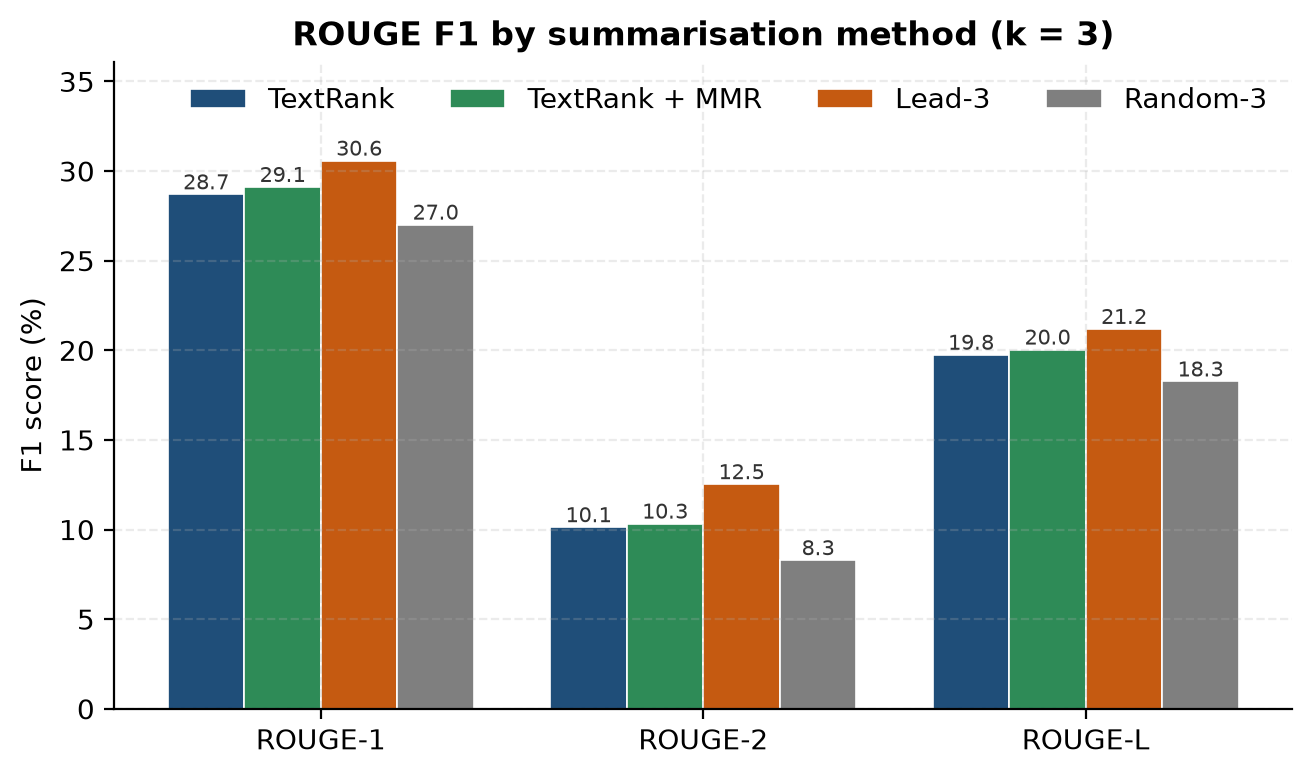

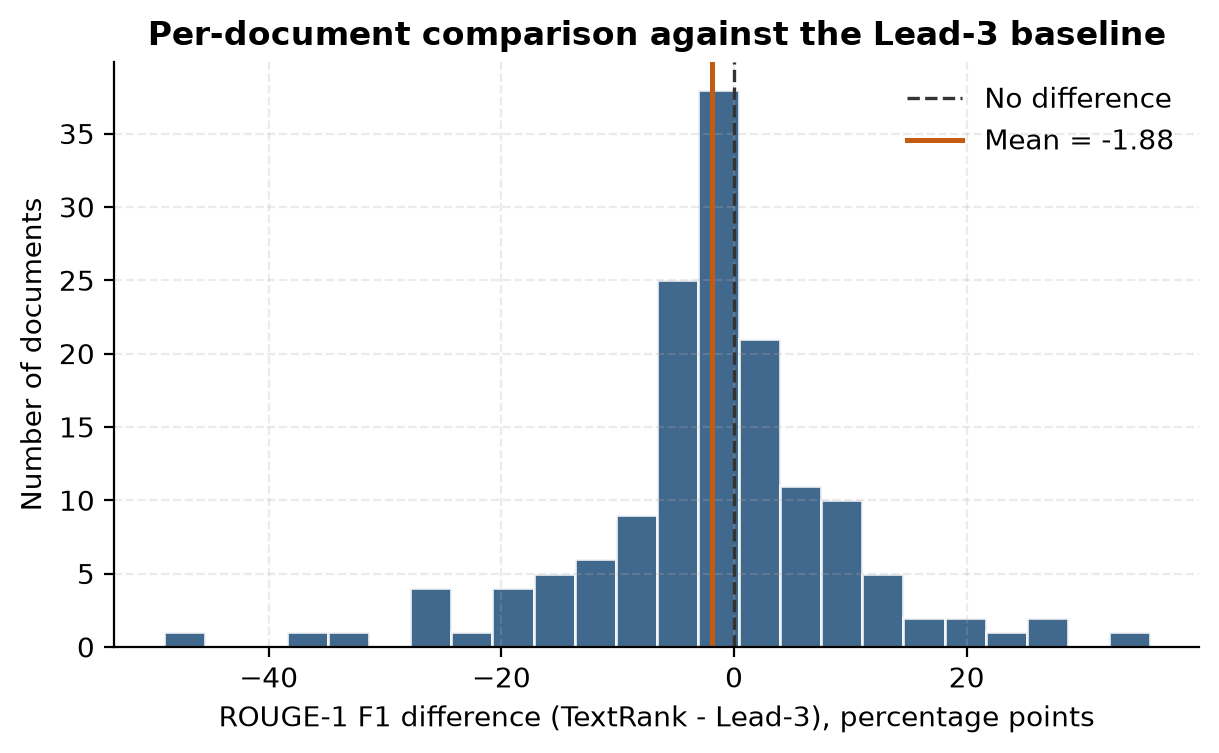

In [8]:
summary = results["summary_k3"].set_index("method")
comparisons = pd.DataFrame(results["comparisons"])
comparisons["mean_difference_pp"] = comparisons["mean_difference"] * 100
comparisons["ci_low_pp"] = comparisons["ci_low"] * 100
comparisons["ci_high_pp"] = comparisons["ci_high"] * 100

table = comparisons[
    ["method_a", "method_b", "metric", "mean_a", "mean_b", "mean_difference_pp",
     "ci_low_pp", "ci_high_pp", "a_wins", "b_wins", "p_value"]
].copy()
table[["mean_a", "mean_b"]] = (table[["mean_a", "mean_b"]] * 100).round(2)
table[["mean_difference_pp", "ci_low_pp", "ci_high_pp"]] = table[
    ["mean_difference_pp", "ci_low_pp", "ci_high_pp"]
].round(2)
table["p_value"] = table["p_value"].map(lambda value: f"{value:.4f}" if pd.notna(value) else "n/a")
display(
    table.rename(
        columns={
            "method_a": "Method A", "method_b": "Method B", "metric": "Metric",
            "mean_a": "A (%)", "mean_b": "B (%)", "mean_difference_pp": "Difference (pp)",
            "ci_low_pp": "95% CI low", "ci_high_pp": "95% CI high",
            "a_wins": "A wins", "b_wins": "B wins", "p_value": "Wilcoxon p",
        }
    ).style.hide(axis="index")
)

textrank1 = summary.loc["TextRank", "rouge1_f1"] * 100
lead1 = summary.loc["Lead-k", "rouge1_f1"] * 100
random1 = summary.loc["Random-k", "rouge1_f1"] * 100
mmr1 = summary.loc["TextRank + MMR", "rouge1_f1"] * 100

display(
    Markdown(
        f"""
**Reading the numbers.** TextRank reaches **{textrank1:.2f} ROUGE-1 F1**, versus
**{lead1:.2f}** for Lead-3 and **{random1:.2f}** for Random-3. The gain over the random
baseline is statistically significant, while the gap to Lead-3 is real and is discussed
in Section 11. Adding redundancy filtering changes ROUGE-1 from {textrank1:.2f} to
{mmr1:.2f}, a difference that is not statistically significant.
"""
    )
)

for filename, width in (("rouge_by_method.png", 700), ("delta_vs_lead3.png", 700)):
    display(Image(filename=str(ROOT / "results" / "figures" / filename), width=width))

<a id="9-analysis"></a>
## 9. Length sweep, ablation and error analysis

A single operating point can hide a lot. The sweep below varies the number of extracted sentences from 2 to 8 and asks whether the ranking of methods is stable. Two effects usually appear:

* **All methods peak at k = 2–3.** As *k* grows, precision falls faster than recall rises, so ROUGE-1 F1 declines for every method and the ordering of methods stays stable.
* **TextRank beats Random-3 at every length.** The graph ranking is consistently more informative than content-blind selection, even though it never overtakes the news-specific Lead baseline.

The per-document comparison then shows *where* TextRank wins: not uniformly, but on articles whose key information is not confined to the opening sentences (background pieces, multi-topic reports, articles with an anecdotal lead).

**ROUGE-1 F1 by summary length**

method,Lead-k,Random-k,TextRank,TextRank + MMR
k,,,,
2,0.313,0.250,0.297,0.301
3,0.306,0.270,0.287,0.291
4,0.298,0.256,0.269,0.271
5,0.277,0.243,0.251,0.253
6,0.258,0.229,0.234,0.236
8,0.226,0.211,0.209,0.210


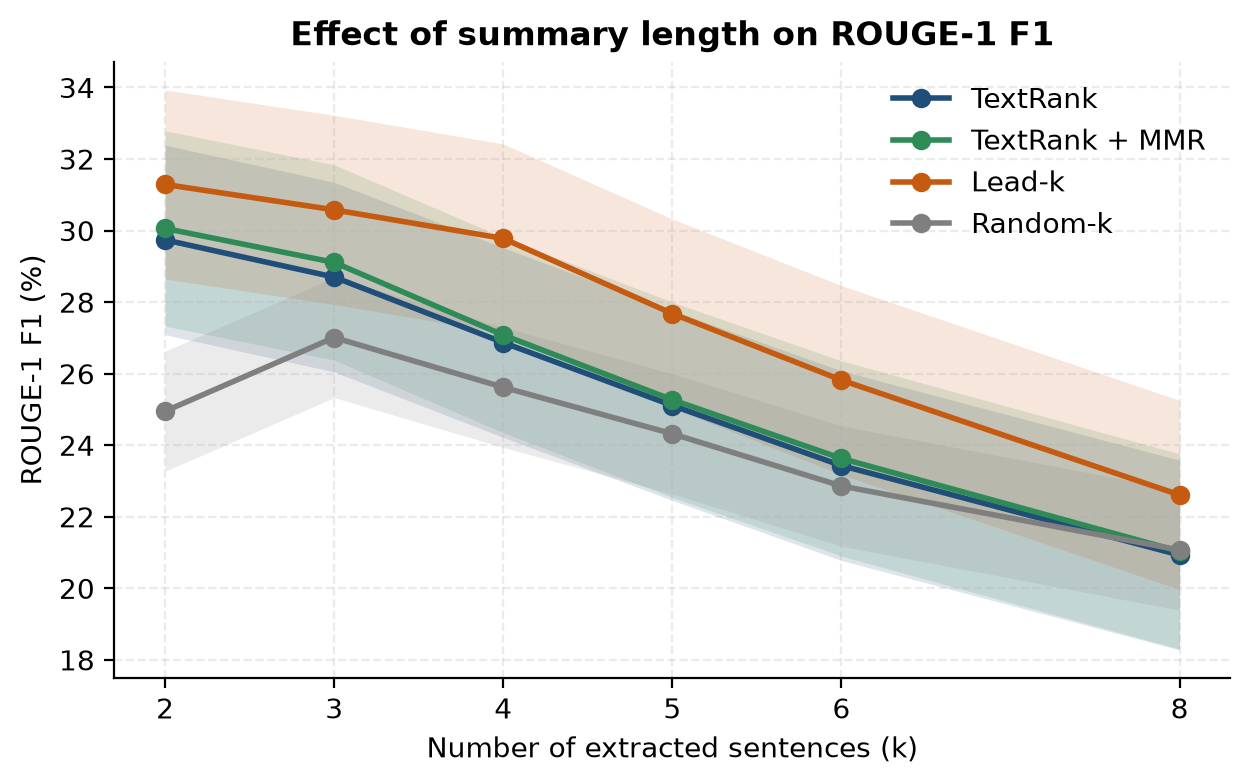

**Precision–recall trade-off (all methods, k = 3)**

method,R-1 precision (%),R-1 recall (%),R-1 F1 (%),Summary words,Compression (%)
TextRank,21.600000,46.510000,28.700000,70.430000,18.500000
TextRank + MMR,21.900000,47.120000,29.110000,70.310000,18.300000
Lead-k,23.280000,48.770000,30.580000,66.500000,17.500000
Random-k,21.460000,39.530000,27.010000,60.260000,16.100000


In [9]:
sweep = results["metrics_by_method_k"]
pivot = sweep.pivot_table(index="k", columns="method", values="rouge1_f1").round(3)
display(Markdown("**ROUGE-1 F1 by summary length**"))
display(pivot)

fig = visualize.plot_metric_by_length(sweep, ROOT / "results" / "figures" / "rouge_by_length.png")
plt.close(fig)
display(Image(filename=str(ROOT / "results" / "figures" / "rouge_by_length.png"), width=720))

display(Markdown("**Precision–recall trade-off (all methods, k = 3)**"))
tradeoff = results["summary_k3"][
    ["method", "rouge1_precision", "rouge1_recall", "rouge1_f1", "summary_words", "compression_ratio"]
].copy()
tradeoff[["rouge1_precision", "rouge1_recall", "rouge1_f1"]] *= 100
tradeoff["compression_ratio"] = (tradeoff["compression_ratio"] * 100).round(1)
display(tradeoff.round(2).rename(columns={
    "rouge1_precision": "R-1 precision (%)", "rouge1_recall": "R-1 recall (%)",
    "rouge1_f1": "R-1 F1 (%)", "summary_words": "Summary words", "compression_ratio": "Compression (%)",
}).style.hide(axis="index"))

### Ablation: does redundancy filtering help?

method,TextRank,TextRank + MMR
k,,
2,0.297,0.301
3,0.287,0.291
4,0.269,0.271
5,0.251,0.253
6,0.234,0.236
8,0.209,0.210


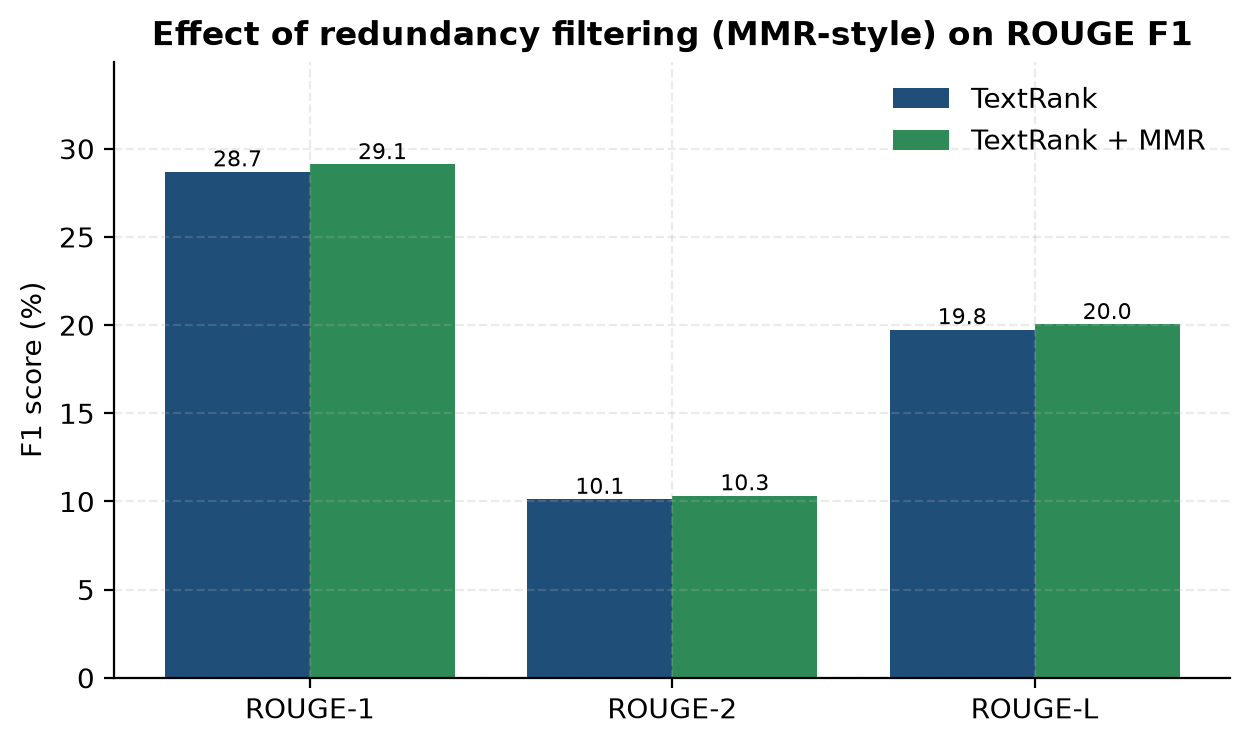

In [10]:
display(Markdown("### Ablation: does redundancy filtering help?"))
ablation = sweep[sweep["method"].isin(["TextRank", "TextRank + MMR"])]
ablation_pivot = ablation.pivot_table(index="k", columns="method", values="rouge1_f1").round(3)
display(ablation_pivot)

fig = visualize.plot_ablation(
    ablation[ablation["k"] == 3], ROOT / "results" / "figures" / "ablation_mmr.png"
)
plt.close(fig)
display(Image(filename=str(ROOT / "results" / "figures" / "ablation_mmr.png"), width=680))

In [11]:
examples = json.loads((ROOT / "results" / "examples.json").read_text(encoding="utf-8"))

for label, heading in (
    ("best_vs_lead", "Largest gain over Lead-3"),
    ("median", "Median document"),
    ("worst_vs_lead", "Largest loss to Lead-3"),
):
    record = examples[label]
    rouge = record["rouge"]
    card = f"""
---
### {heading} — document `{record["doc_id"][:35]}`

**ROUGE-1 F1:** TextRank {rouge.get("TextRank", {}).get("rouge1_f1", 0) * 100:.1f}% &nbsp;|&nbsp;
Lead-3 {rouge.get("Lead-k", {}).get("rouge1_f1", 0) * 100:.1f}%

**TextRank extract**

> {record["textrank"]}

**Lead-3 extract**

> {record["lead"]}

**Human reference**

> {record["reference"]}
"""
    display(Markdown(card))

display(
    Markdown(
        """
**Error analysis.** The failure cases share a pattern: the reference summary is written
as a tight, abstractive paraphrase, while the extractor can only copy whole sentences.
A selected sentence may contain the right fact *plus* several irrelevant clauses, so
unigram precision drops even when the fact is present. Conversely, the wins usually
come from articles where the lede is scene-setting and the actual news appears later.
"""
    )
)


---
### Largest gain over Lead-3 — document `6344c9689865cf86da50fbe90acf13c3407`

**ROUGE-1 F1:** TextRank 47.5% &nbsp;|&nbsp;
Lead-3 11.8%

**TextRank extract**

> Cifuentes' case is dramatic, but in Guatemala, where nearly 10 out of every 100,000 women are killed, it's hardly unusual. A 2012 Small Arms Survey says gender-based violence is at epidemic levels in Guatemala and the country ranks third in the killings of women worldwide. According to the United Nations, two women are killed there every day.

**Lead-3 extract**

> For 12 years Adelma Cifuentes felt worthless, frightened and alone, never knowing when her abusive husband would strike. But as a young mother in rural Guatemala with three children and barely a third grade education, she thought there was no way out. What began as psychological torment, name-calling and humiliation turned into beatings so severe Cifuentes feared for her life.

**Human reference**

> Gender-based violence is at epidemic levels in Guatemala . According to the United Nations, two women are killed in Guatemala every day . Five abuse survivors known as La Poderosas have been appearing in a play based on their real life stories .



---
### Median document — document `8be49747e364357d7c5d32fca516ec230e5`

**ROUGE-1 F1:** TextRank 45.8% &nbsp;|&nbsp;
Lead-3 46.9%

**TextRank extract**

> A University of Kentucky basketball player is apologizing for the "poor choice of words" he muttered under his breath after the team's stunning loss to Wisconsin on Saturday. Harrison, who is is black, said his words were "in jest," and that he meant no disrespect to Kaminsky, who is white. "First I want to apologize for my poor choice of words used in jest towards a player I respect and know," Harrison tweeted.

**Lead-3 extract**

> A University of Kentucky basketball player is apologizing for the "poor choice of words" he muttered under his breath after the team's stunning loss to Wisconsin on Saturday. As a deflated panel of Wildcats fielded a reporter's question about Wisconsin standout Frank Kaminsky, a hot mic picked up Kentucky guard Andrew Harrison saying of Kaminsky, "F**k that (N-word)." Harrison, who is is black, said his words were "in jest," and that he meant no disrespect to Kaminsky, who is white.

**Human reference**

> Kentucky player mutters N-word under his breath about a Wisconsin player at postgame news conference . Andrew Harrison, who is black, tweets that he apologized to Frank Kaminsky, who is white . Kaminsky says he's talked it over with Harrison -- 'I'm over it"



---
### Largest loss to Lead-3 — document `84dabfdd73c25b81b7ea0ce23e74638cc6c`

**ROUGE-1 F1:** TextRank 20.8% &nbsp;|&nbsp;
Lead-3 69.8%

**TextRank extract**

> "Without men, it is not possible for women to get their rights," she says. "And you have to struggle for your rights. Who will get the rights for us?

**Lead-3 extract**

> An Amnesty International report is calling for authorities to address the number of attacks on women's rights activists in Afghanistan. The report, entitled "Their Lives on the Line," examines the persecution of activists and other champions of women's rights not only by the Taliban and tribal warlords, but also by government officials. Its publication is timely.

**Human reference**

> An Amnesty International report calls for attacks on women's rights activists in Afghanistan to be investigated . The report examines the persecution of activists not only by the Taliban and tribal warlords, but also by government officials . Some activists continue their work despite their lives being at risk .



**Error analysis.** The failure cases share a pattern: the reference summary is written
as a tight, abstractive paraphrase, while the extractor can only copy whole sentences.
A selected sentence may contain the right fact *plus* several irrelevant clauses, so
unigram precision drops even when the fact is present. Conversely, the wins usually
come from articles where the lede is scene-setting and the actual news appears later.


<a id="10-streamlit-demo"></a>
## 10. Streamlit demonstration

The same pipeline is exposed as an interactive web app (`src/app.py`). It accepts pasted text or a `.txt` upload, lets the user choose the method, summary length, damping factor and similarity threshold, and shows:

* the generated summary beside the reference summary;
* ROUGE-1/2/L cards with the delta against Lead-*k*;
* the PageRank sentence ranking, the similarity heatmap and the sentence graph;
* a download button for the summary.

Run it with:

```bash
streamlit run src/app.py
```

Screenshots below were captured automatically from the running app (`scripts/capture_app.py`) and are also compiled into `deliverables/output_screenshots.pdf`.

**App Overview**

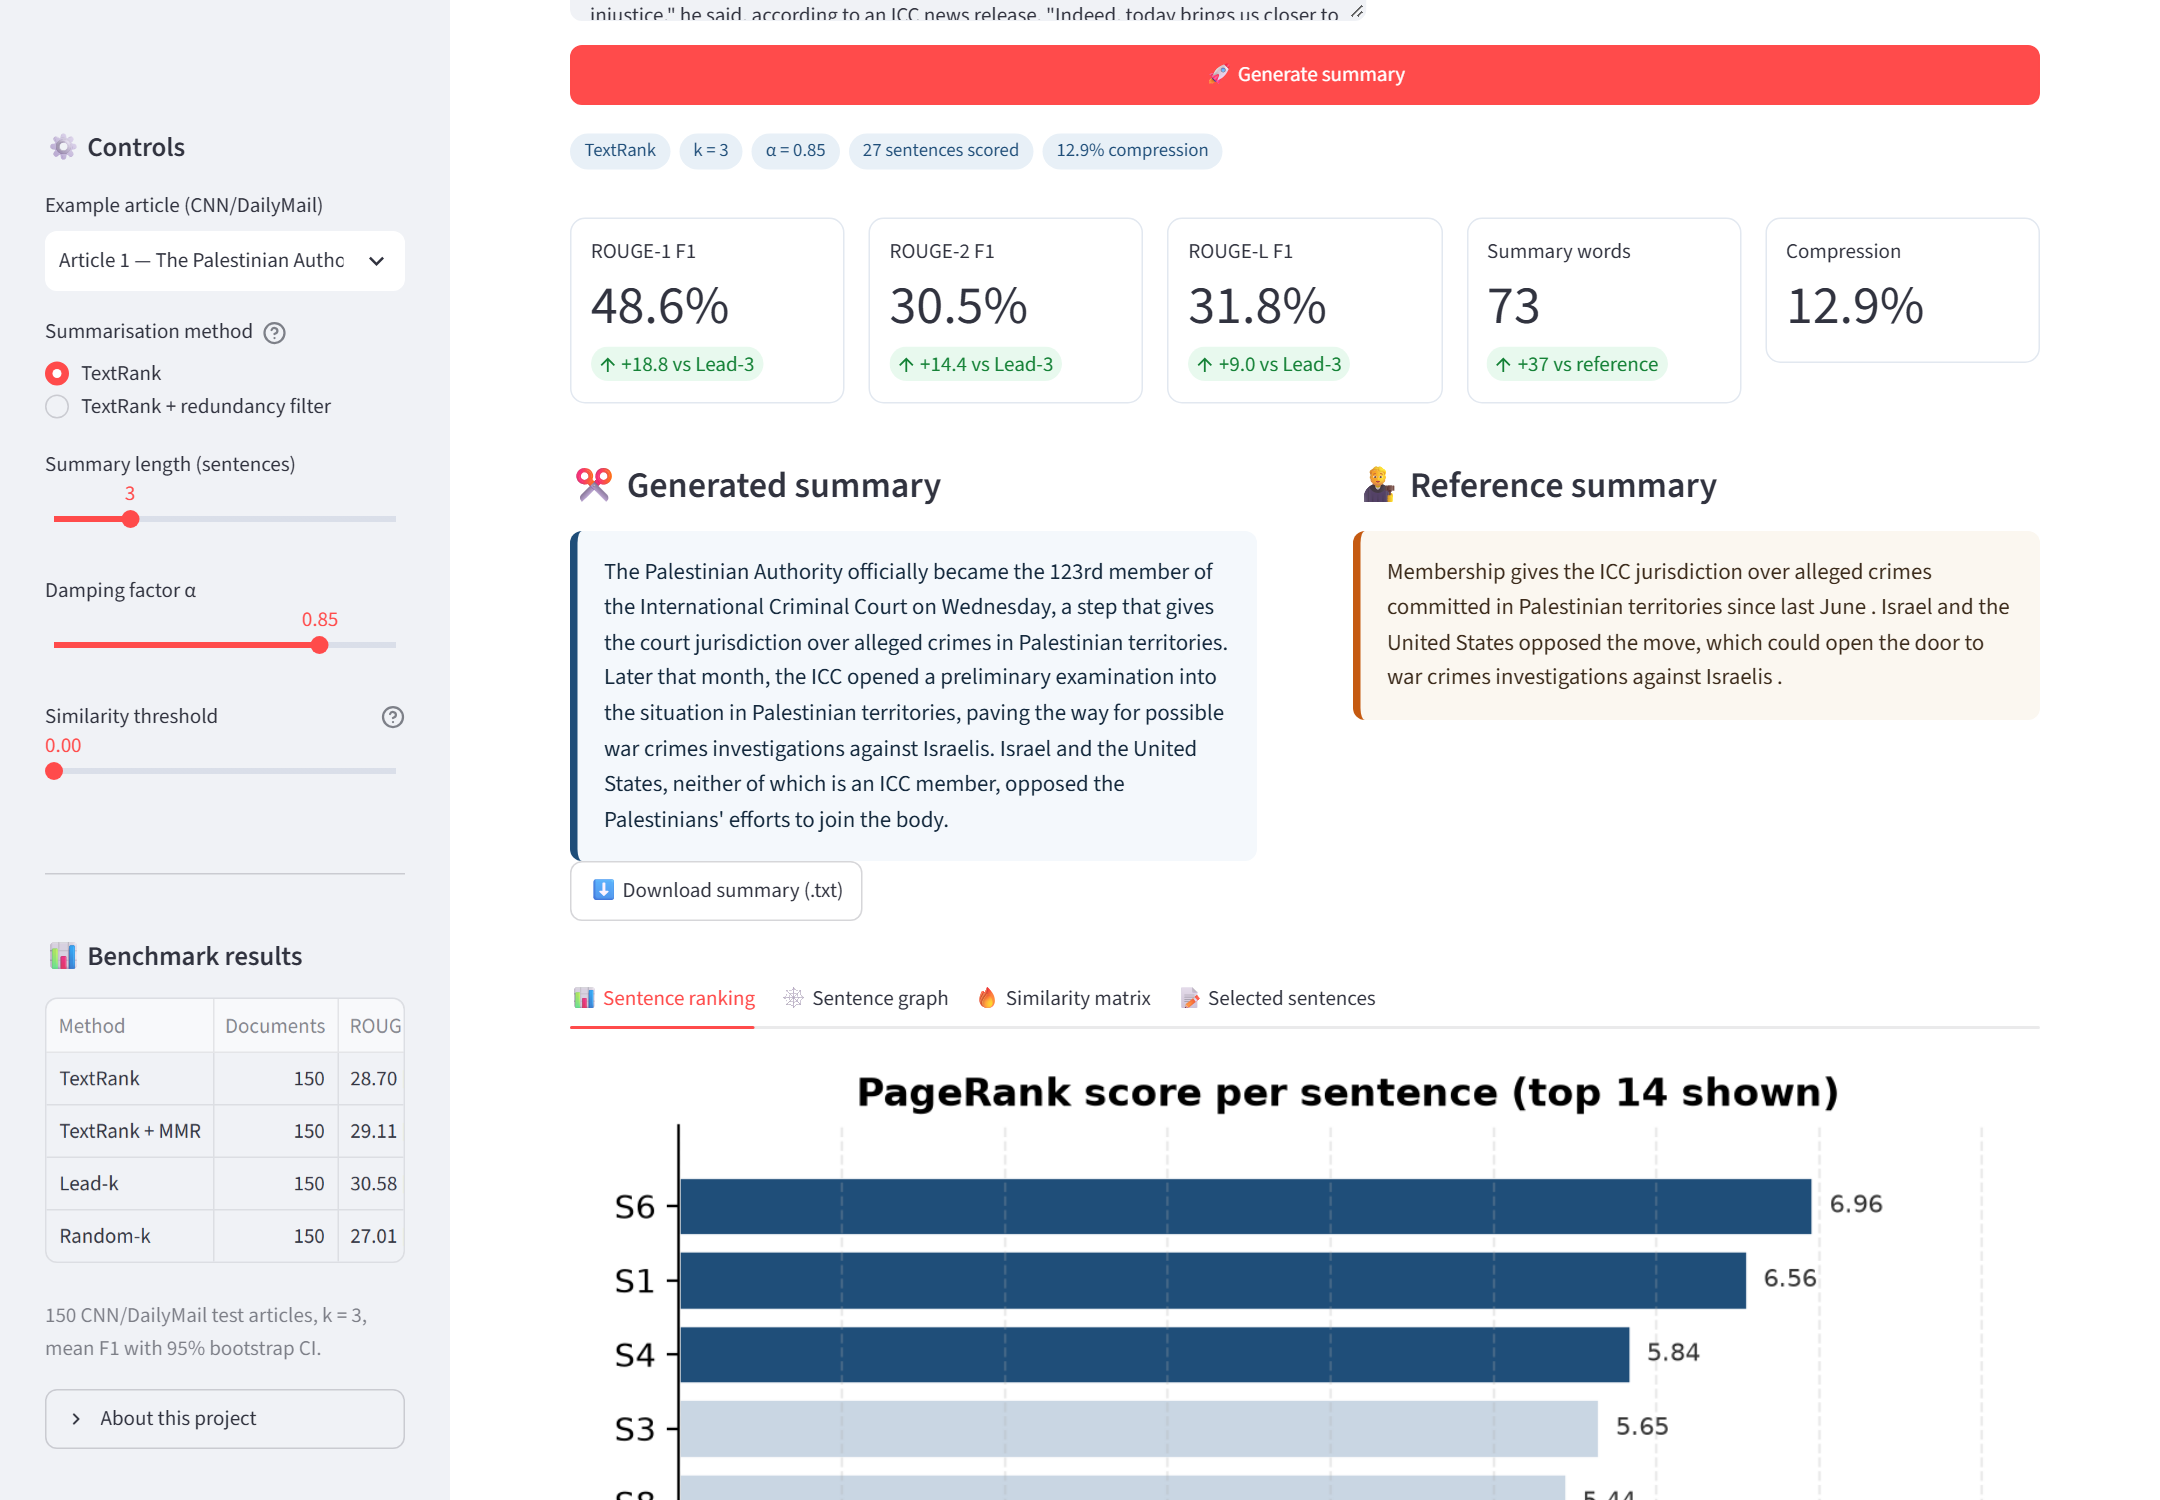

**App Sentence Ranking**

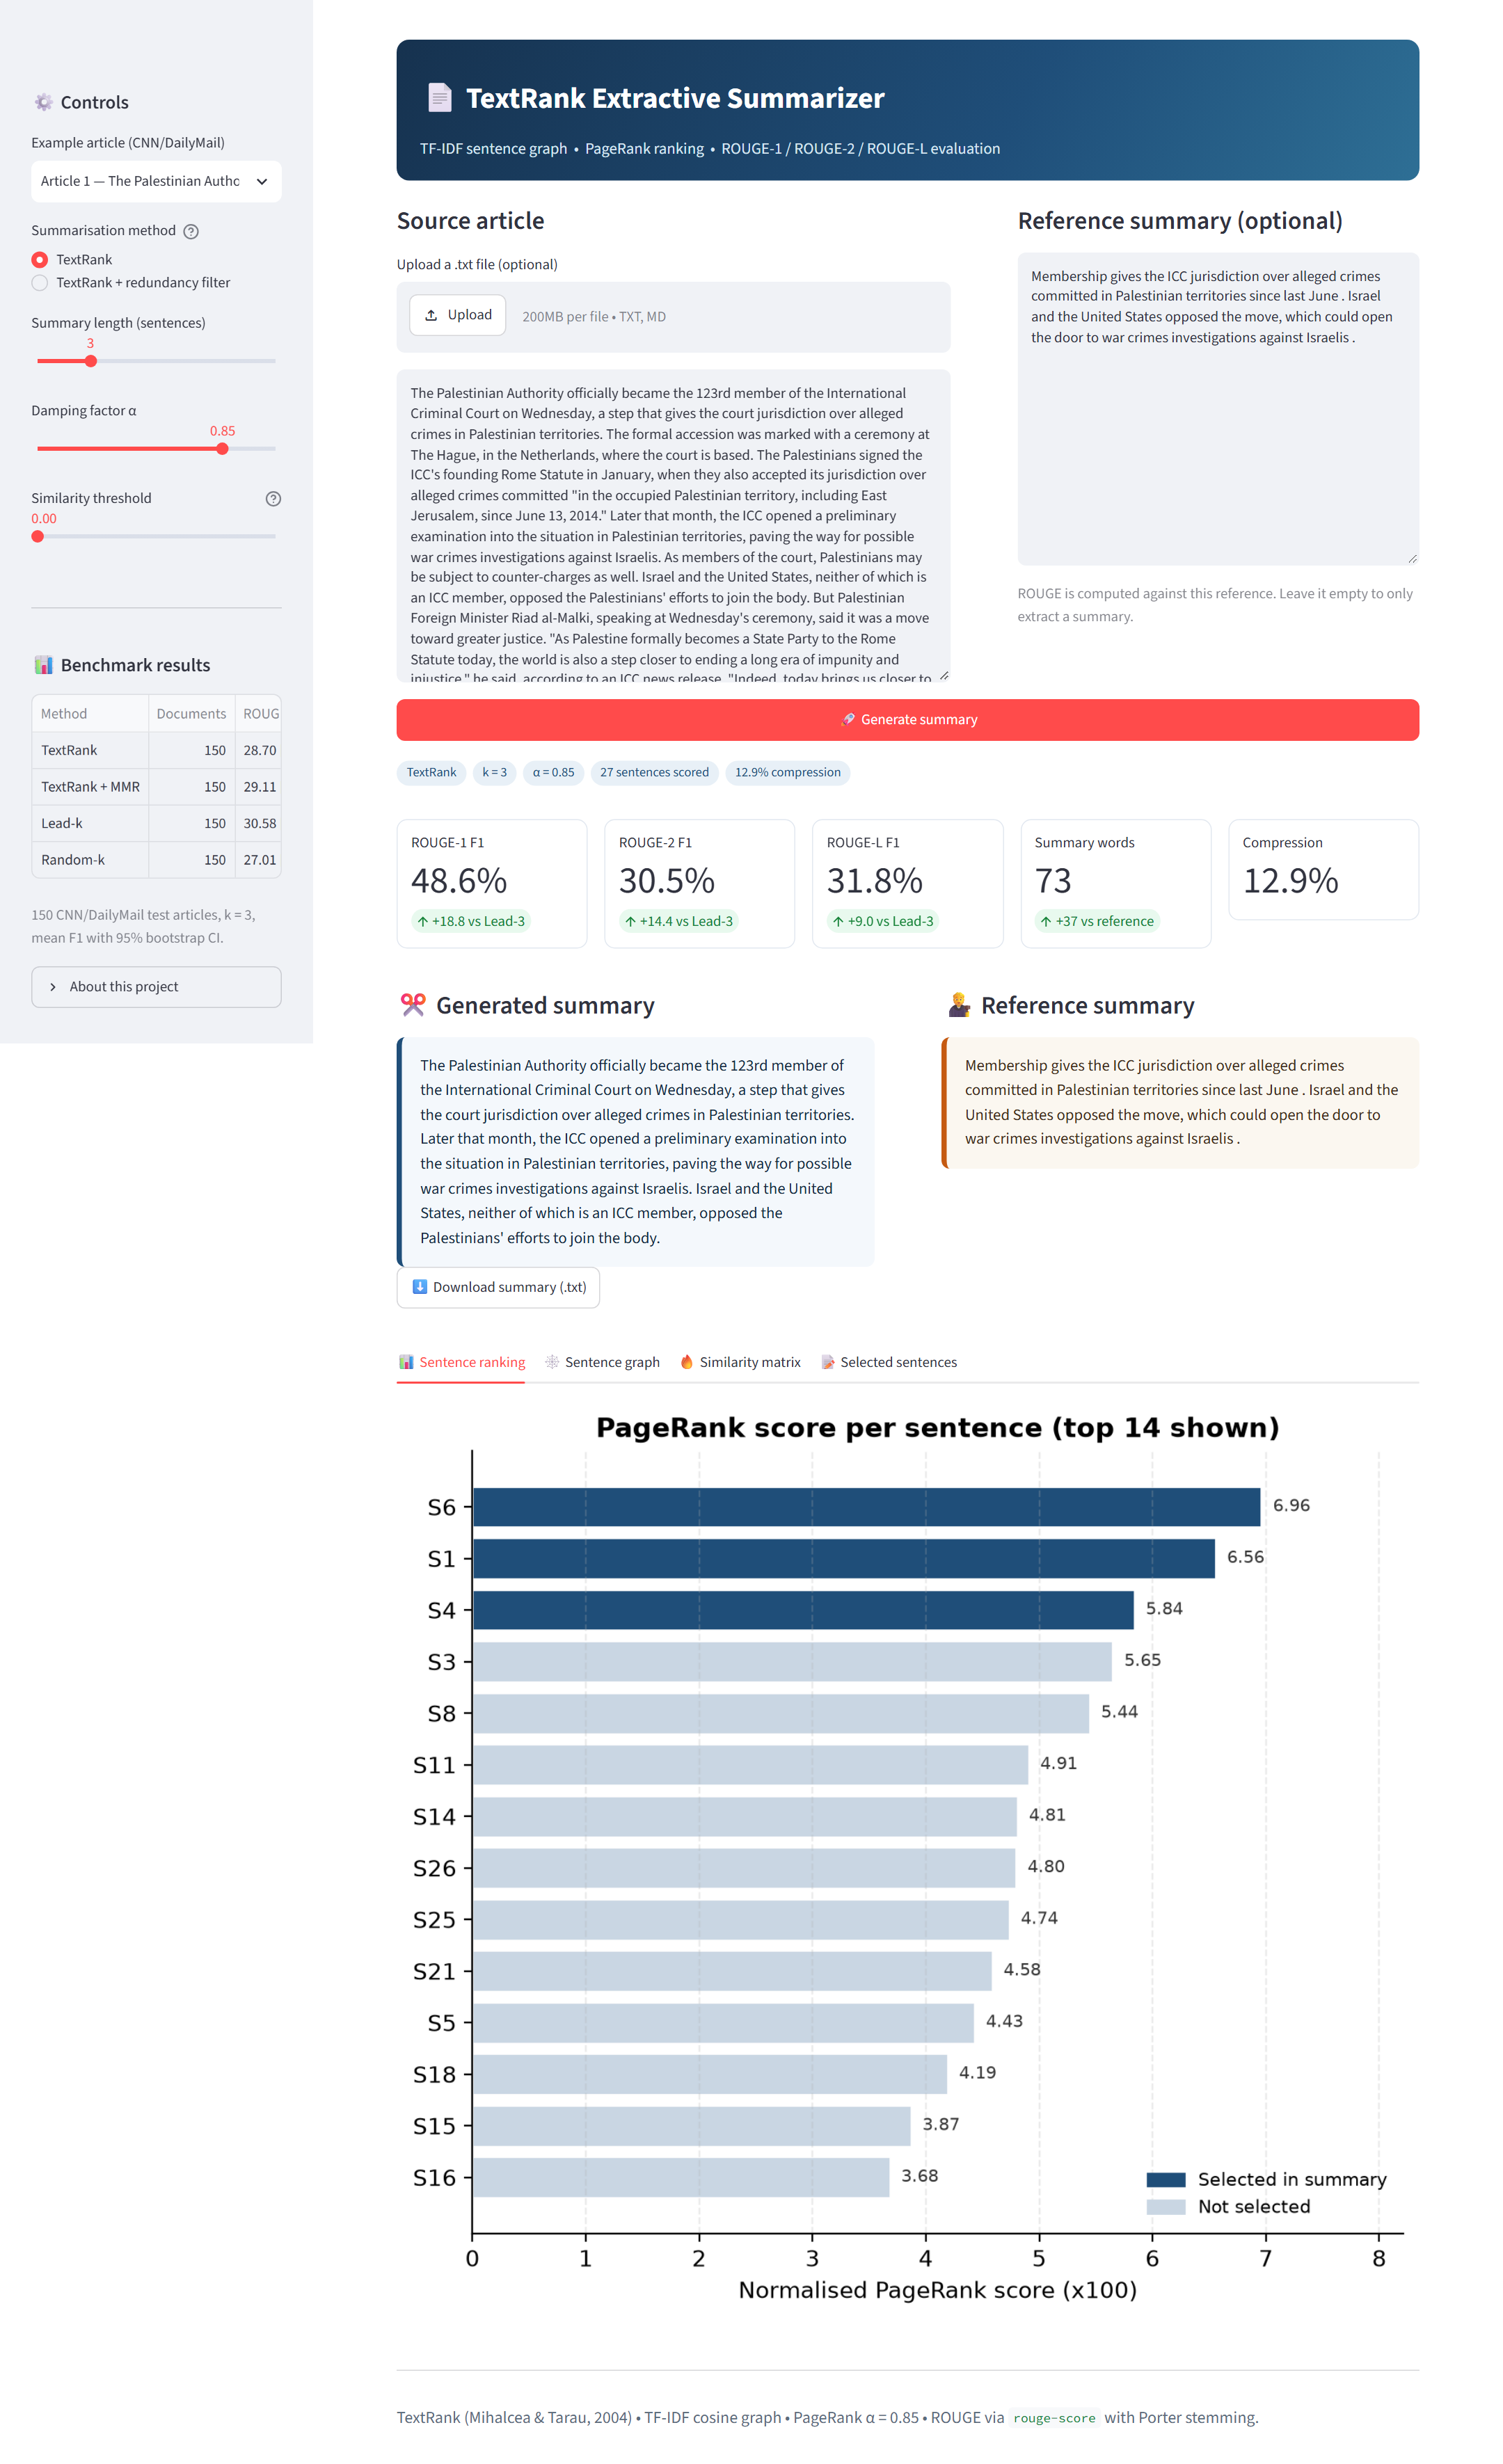

**App Sentence Graph**

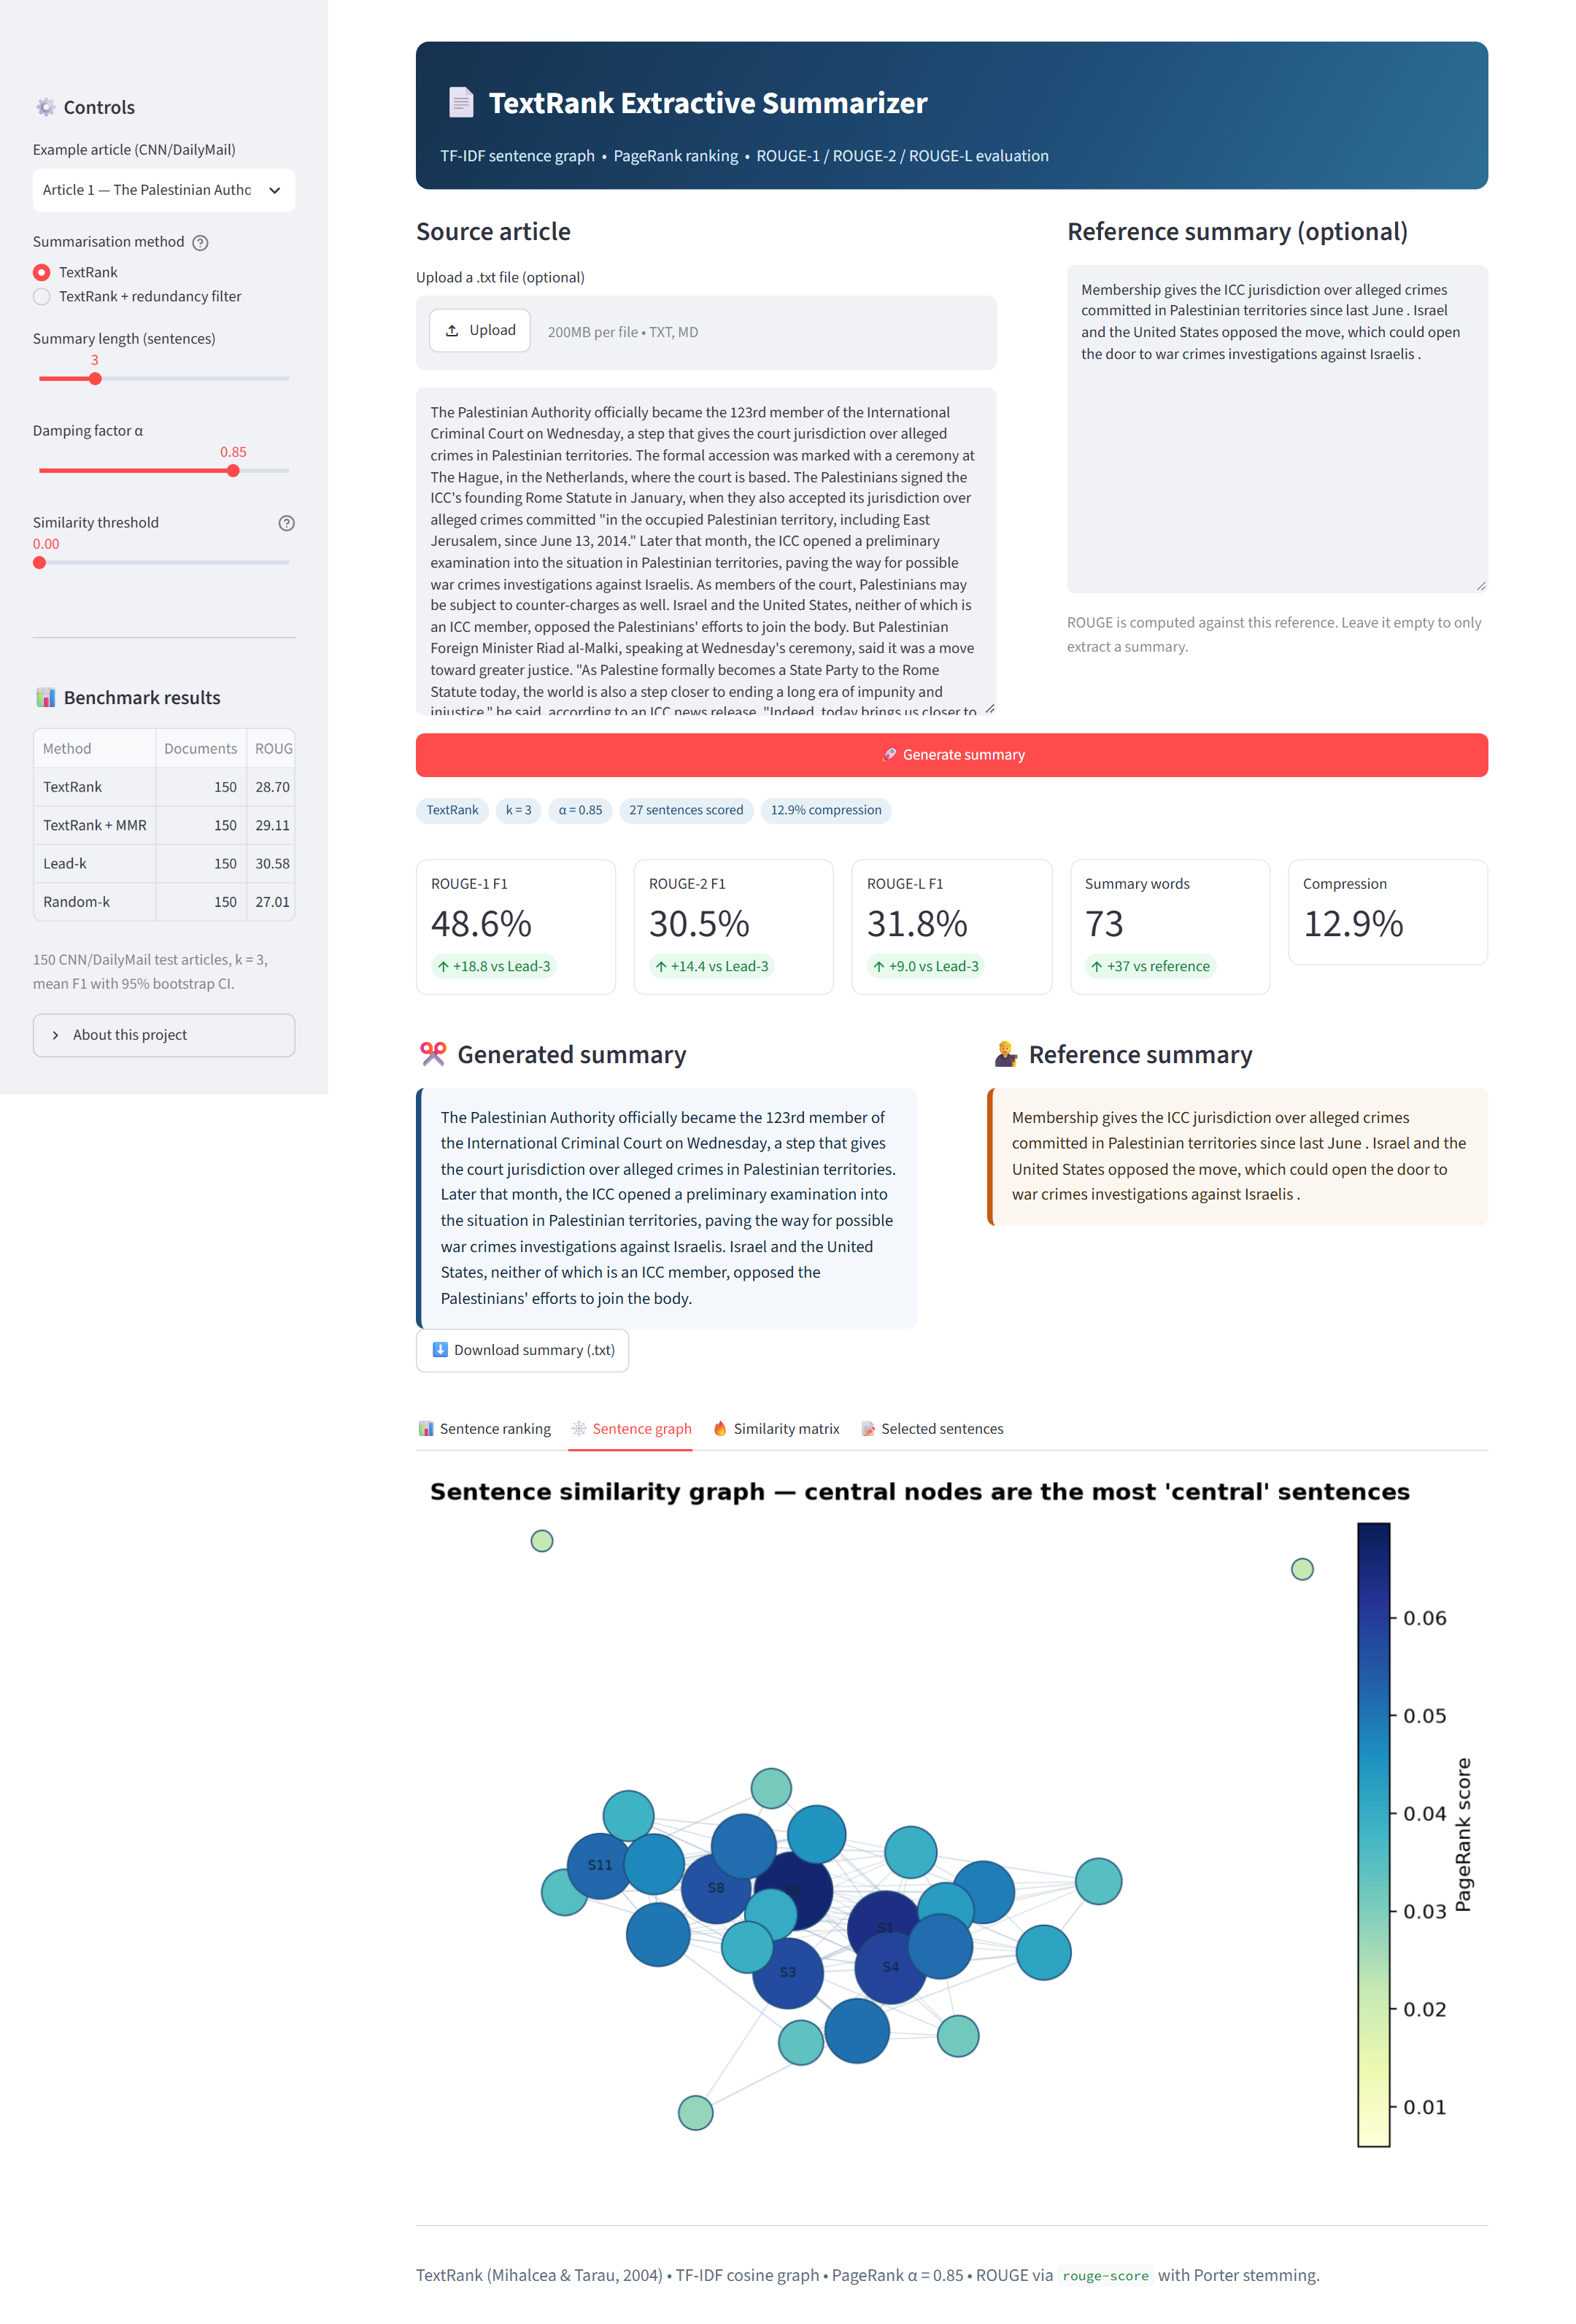

In [12]:
for filename, width in (
    ("app_overview.png", 900),
    ("app_sentence_ranking.png", 900),
    ("app_sentence_graph.png", 900),
):
    path = ROOT / "results" / "figures" / filename
    if path.exists():
        display(Markdown(f"**{filename.replace('_', ' ').replace('.png', '').title()}**"))
        display(Image(filename=str(path), width=width))

<a id="11-discussion"></a>
## 11. Discussion, limitations and conclusion

### Why does Lead-3 beat TextRank here?

CNN/DailyMail is not a neutral test of summarisation quality. News writing concentrates the who/what/when in the first two or three sentences, and the human highlights were written by editors who had the full article but followed the same news convention. Lead-3 therefore has an implicit prior that matches the data-generating process almost perfectly. TextRank, which is position-agnostic, spends part of its budget on sentences that are central to the article's *topic* but absent from the reference — for example, background or reaction paragraphs. This is a well-documented result, not a failure peculiar to this implementation.

The comparison that isolates algorithmic value is the one against **Random-3**, and there TextRank wins consistently and significantly on all three metrics, at every summary length tested. The length sweep shows that all methods peak at two or three sentences and then decline as precision falls faster than recall rises; the gap to Lead-3 is smallest at the shortest and longest settings and largest in the middle of the range.

### What would improve the system?

1. **Position prior.** Add a small positional decay to the PageRank score, or initialise the PageRank vector with a lead bias. This is a hybrid extractor and typically closes much of the gap to Lead-3.
2. **Better sentence representations.** Sentence-BERT or GloVe embeddings capture paraphrase similarity that TF-IDF misses, especially for abstractive references.
3. **Redundancy-aware selection.** A proper MMR objective or a maximal-marginal-relevance reranker (rather than the threshold filter used here) would help on longer summaries.
4. **Reference-aware length.** Choose *k* per document from the predicted reference length instead of fixing it globally.
5. **Broader evaluation.** Add BERTScore or human ratings; ROUGE rewards lexical overlap and penalises legitimate paraphrases.

### Limitations

* The evaluation slice is 150 test articles, so confidence intervals are reported rather than single-point claims.
* ROUGE with one reference is a lower bound on quality: a correct extract that paraphrases the reference can score zero on ROUGE-2.
* TextRank is unsupervised and cannot perform abstraction, pronoun resolution or sentence fusion; the output is always a subset of the source sentences.
* The redundancy threshold (0.30) was chosen from the similarity distribution, not tuned on the test set; it is an ablation, not a tuned hyperparameter.

### Conclusion

This project implemented TextRank from first principles — sentence segmentation, TF-IDF representation, cosine-similarity graph construction, PageRank with $d=0.85$, ranked extraction and chronological re-ordering — and evaluated it against human summaries with ROUGE-1, ROUGE-2 and ROUGE-L. TextRank beats a random extractor by a statistically significant margin and remains competitive with the strongest news-specific baseline, while the analysis explains precisely why Lead-3 is hard to beat on CNN/DailyMail. The complete pipeline, experiment scripts, interactive demo and report are released together so that every number in this notebook can be reproduced with a single command.

## References

1. Mihalcea, R., & Tarau, P. (2004). *TextRank: Bringing Order into Texts.* EMNLP 2004.
2. Page, L., Brin, S., Motwani, R., & Winograd, T. (1999). *The PageRank Citation Ranking: Bringing Order to the Web.* Stanford InfoLab.
3. Lin, C.-Y. (2004). *ROUGE: A Package for Automatic Evaluation of Summaries.* ACL Workshop on Text Summarization Branches Out.
4. Nallapati, R., Zhou, B., Gulcehre, C., & Xiang, B. (2016). *Abstractive Text Summarization using Sequence-to-Sequence RNNs and Beyond.* CoNLL 2016. (CNN/DailyMail benchmark)
5. Hermann, K. M., et al. (2015). *Teaching Machines to Read and Comprehend.* NeurIPS 2015.
6. scikit-learn developers. *TfidfVectorizer documentation.* https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html
7. NetworkX developers. *pagerank documentation.* https://networkx.org/documentation/stable/reference/algorithms/generated/networkx.algorithms.link_analysis.pagerank_alg.pagerank.html
8. Google Research. *rouge-score.* https://github.com/google-research/google-research/tree/master/rouge

## Reproducing this notebook

```bash
# 1. Install dependencies
python -m venv .venv
.venv\Scripts\activate          # Windows
pip install -r requirements.txt

# 2. (Optional) re-download the dataset slice
python scripts/fetch_data.py

# 3. Re-run the experiment and regenerate every figure/table
python scripts/run_experiment.py

# 4. Launch the demo
streamlit run src/app.py
```

### Submission checklist

- [x] Complete Jupyter notebook with executed outputs (this file)
- [x] Source modules (`src/`) and experiment scripts (`scripts/`)
- [x] ROUGE evaluation tables and figures (`results/`)
- [x] Streamlit application and screenshots (`src/app.py`, `results/figures/app_*.png`)
- [x] Term project report PDF (`deliverables/project_report.pdf`)
- [x] Output screenshots PDF (`deliverables/output_screenshots.pdf`)
- [x] Demo video MP4 (2–3 minutes)
- [x] Public GitHub repository — github.com/sriramrameshr/textrank-summarizer